In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score, f1_score,
    precision_recall_curve, ConfusionMatrixDisplay,
)
from xgboost import XGBClassifier

In [3]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

# Clues (X) and answer (y) for the training file
X = train.drop(columns=["Class"])
y = train["Class"]

# Same split as the previous notebook (same settings = same rows)
X_fit, X_val, y_fit, y_val = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

# Clues and answer for the test file. We won't touch these until step 4.
X_test = test.drop(columns=["Class"])
y_test = test["Class"]

print(f"Learn: {len(X_fit):,} rows ({y_fit.sum()} frauds)")
print(f"Validation: {len(X_val):,} rows ({y_val.sum()} frauds)")
print(f"Test (locked): {len(X_test):,} rows ({y_test.sum()} frauds)")

Learn: 170,235 rows (284 frauds)
Validation: 56,745 rows (94 frauds)
Test (locked): 56,746 rows (95 frauds)


In [4]:
# How many legit rows there are for every fraud row
ratio = (y_fit == 0).sum() / (y_fit == 1).sum()

model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=ratio,
    eval_metric="aucpr",
    tree_method="hist",
    n_jobs=-1,
    random_state=42,
)
model.fit(X_fit, y_fit)

# Fraud probabilities on the validation set (used to choose the threshold)
val_prob = model.predict_proba(X_val)[:, 1]
print("PR-AUC on validation:", round(average_precision_score(y_val, val_prob), 3))

PR-AUC on validation: 0.882


Cost-based threshold (we will use this): 0.3300
Best-F1 threshold (for comparison):      0.9962


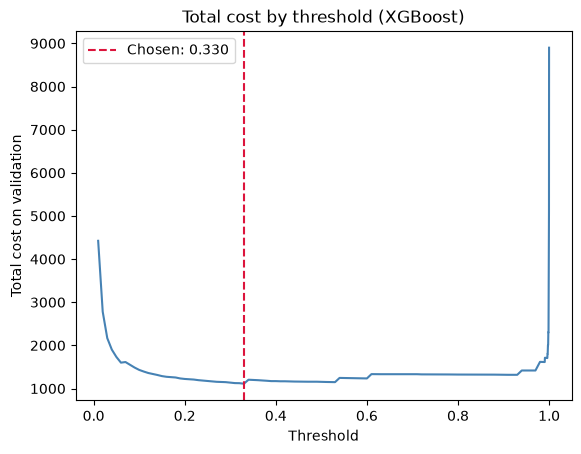

In [5]:
# taking assumptions here tbf
COST_MISSED_FRAUD = 100
COST_FALSE_ALARM = 2

yv = y_val.values   # plain array of the validation answers, easier to do maths with


def outcomes(y_true, prob, threshold):
    # Count the four outcomes at a given threshold
    pred = prob >= threshold                      # True where we flag fraud
    tp = int((pred & (y_true == 1)).sum())        # fraud correctly flagged
    fp = int((pred & (y_true == 0)).sum())        # legit wrongly flagged (false alarm)
    fn = int((~pred & (y_true == 1)).sum())       # fraud missed
    tn = int((~pred & (y_true == 0)).sum())       # legit correctly left alone
    return tp, fp, fn, tn


def total_cost(fn, fp):
    return fn * COST_MISSED_FRAUD + fp * COST_FALSE_ALARM


# Thresholds to try: 99 even steps from 0.01 to 0.99, plus 50 finer steps from 0.99 to 0.9999
grid = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), np.linspace(0.99, 0.9999, 50)]))

costs = []
for t in grid:
    tp, fp, fn, tn = outcomes(yv, val_prob, t)
    costs.append(total_cost(fn, fp))

# argmin gives the position of the smallest cost
chosen_threshold = float(grid[int(np.argmin(costs))])

# For comparison: the threshold with the best F1
prec, rec, thr = precision_recall_curve(y_val, val_prob)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
f1_threshold = float(thr[int(np.argmax(f1))])

print(f"Cost-based threshold (we will use this): {chosen_threshold:.4f}")
print(f"Best-F1 threshold (for comparison):      {f1_threshold:.4f}")

plt.plot(grid, costs, color="steelblue")
plt.axvline(chosen_threshold, color="crimson", linestyle="--", label=f"Chosen: {chosen_threshold:.3f}")
plt.xlabel("Threshold")
plt.ylabel("Total cost on validation")
plt.title("Total cost by threshold (XGBoost)")
plt.legend()
plt.show()

TEST RESULTS at threshold 0.3300
Precision: 0.541
Recall:    0.832
F1:        0.656
PR-AUC:    0.823


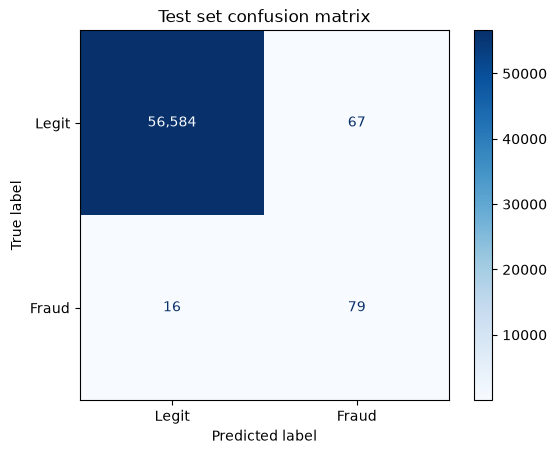


                 Option  Frauds caught  Frauds missed  False alarms  Total cost
No model (flag nothing)              0             95             0        9500
  Default threshold 0.5             77             18            30        1860
       Chosen threshold             79             16            67        1734


In [6]:
# Fraud probabilities on the test set. The model has never seen these rows.
test_prob = model.predict_proba(X_test)[:, 1]
yt = y_test.values

# Apply the locked-in threshold: True/False -> 1/0
test_pred = (test_prob >= chosen_threshold).astype(int)

precision = precision_score(y_test, test_pred)
recall = recall_score(y_test, test_pred)
f1_test = f1_score(y_test, test_pred)
pr_auc = average_precision_score(y_test, test_prob)

print(f"TEST RESULTS at threshold {chosen_threshold:.4f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1:        {f1_test:.3f}")
print(f"PR-AUC:    {pr_auc:.3f}")

# Confusion matrix picture
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Legit", "Fraud"], cmap="Blues", values_format=","
)
plt.title("Test set confusion matrix")
plt.grid(False)
plt.show()

# Compare three options side by side, using the same cost numbers
rows = []
n_fraud = int(yt.sum())
rows.append({"Option": "No model (flag nothing)", "Frauds caught": 0, "Frauds missed": n_fraud,
             "False alarms": 0, "Total cost": total_cost(n_fraud, 0)})
for label, t in [("Default threshold 0.5", 0.5), ("Chosen threshold", chosen_threshold)]:
    tp, fp, fn, tn = outcomes(yt, test_prob, t)
    rows.append({"Option": label, "Frauds caught": tp, "Frauds missed": fn,
                 "False alarms": fp, "Total cost": total_cost(fn, fp)})
print()
print(pd.DataFrame(rows).to_string(index=False))

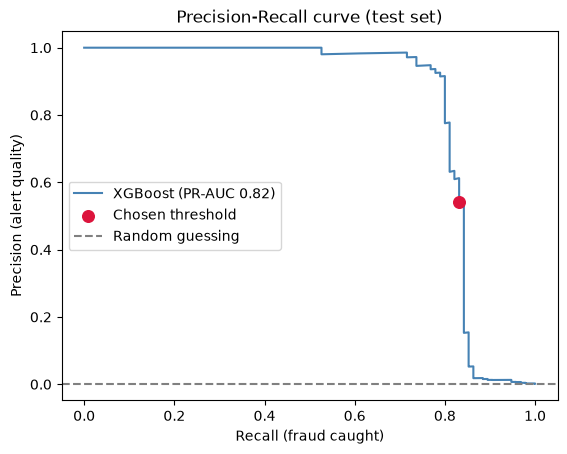

In [7]:
prec_t, rec_t, _ = precision_recall_curve(y_test, test_prob)

plt.plot(rec_t, prec_t, color="steelblue", label=f"XGBoost (PR-AUC {pr_auc:.2f})")
plt.scatter([recall], [precision], color="crimson", s=70, zorder=5, label="Chosen threshold")
plt.axhline(y_test.mean(), color="grey", linestyle="--", label="Random guessing")
plt.xlabel("Recall (fraud caught)")
plt.ylabel("Precision (alert quality)")
plt.title("Precision-Recall curve (test set)")
plt.legend()
plt.show()

In [8]:
tp, fp, fn, tn = outcomes(yt, test_prob, chosen_threshold)
flagged = tp + fp
flagged_pct = flagged / len(yt) * 100

print(f"The model flags {flagged:,} of {len(yt):,} transactions ({flagged_pct:.2f}%) for review.")
print(f"That catches {tp} of {tp + fn} frauds ({recall * 100:.0f}% of all fraud).")
print(f"{precision * 100:.0f}% of the alerts are real fraud, so about {fp} legit transactions get flagged.")

# Guard against dividing by zero if no frauds were caught
if tp > 0:
    print(f"That is about {fp / tp:.1f} false alarms for every fraud caught.")

The model flags 146 of 56,746 transactions (0.26%) for review.
That catches 79 of 95 frauds (83% of all fraud).
54% of the alerts are real fraud, so about 67 legit transactions get flagged.
That is about 0.8 false alarms for every fraud caught.


V14    0.295
V10    0.147
V12    0.078
V4     0.065
V8     0.041
V19    0.028
V20    0.027
V13    0.027
V3     0.026
V21    0.023
dtype: float32


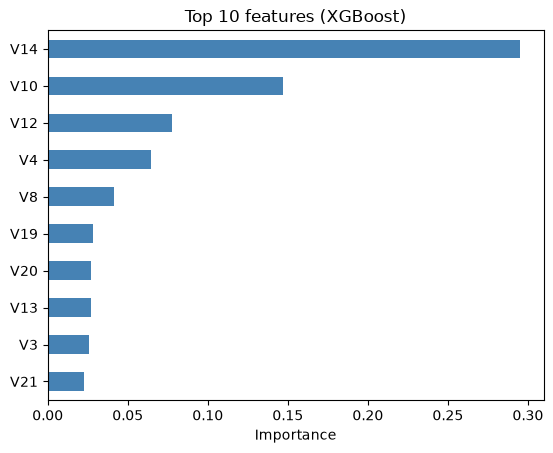

In [9]:
# Pair each feature name with its importance score, sort largest first, keep the top 10
importance = pd.Series(model.feature_importances_, index=X_fit.columns).sort_values(ascending=False)
print(importance.head(10).round(3))

# Plot the top 10. [::-1] reverses the order so the biggest bar ends up at the top.
importance.head(10)[::-1].plot(kind="barh", color="steelblue")
plt.xlabel("Importance")
plt.title("Top 10 features (XGBoost)")
plt.show()

In [ ]:
# using ojblib to keep the model and threshold together
joblib.dump({"model": model, "threshold": chosen_threshold, "columns": list(X_fit.columns)},
            "fraud_xgb_model.joblib")

# Savin the test results -- real answer, model's probability, and the yes/no decision
pd.DataFrame({
    "Class": yt,
    "fraud_probability": test_prob,
    "flagged": test_pred,
}).to_csv("test_predictions.csv", index=False)

print("Saved fraud_xgb_model.joblib and test_predictions.csv")

Saved fraud_xgb_model.joblib and test_predictions.csv
